# Lession 6.3 - Random Forest

**Objectives**:

- Understand `sliding window` and how to turn a time series dataset into input-output paris
- Understand how to split time-series data into training and testing sets by year (no `random shuffle`)
- Build a `random forest` regression model to predict next year's `co2 emission`
- Understand why a random forest can't predict values outside its training range (extrapolation)
- Fix the extrapolation problem by predicting the yearly `co2 growth` instead of the absolute value
- Evaluate models with `R²` and crossplots, and compare them with a simple baseline

## 1. Import python packages: matplotlib, pandas, numpy ...

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

## 2. Read CO2 emission data from csv file

In [2]:
data_file_path = "../../data/owid-co2-data.csv"
co2_emission = pd.read_csv(data_file_path, sep=",")

In [3]:
world_co2_df = (
    co2_emission.loc[
        co2_emission["country"] == "World",
        [
            "year",
            "co2",
        ],
    ]
    .sort_values(by="year", ascending=True)
    .dropna(
        subset=[
            "co2",
        ]
    )
    .reset_index(drop=True)
)

In [4]:
world_co2_df

,year,co2
0,1750,9.306
1,1751,9.407
2,1752,9.505
3,1753,9.610
4,1754,9.734
...,...,...
270,2020,35158.230
271,2021,36866.863
272,2022,37527.773
273,2023,38094.039


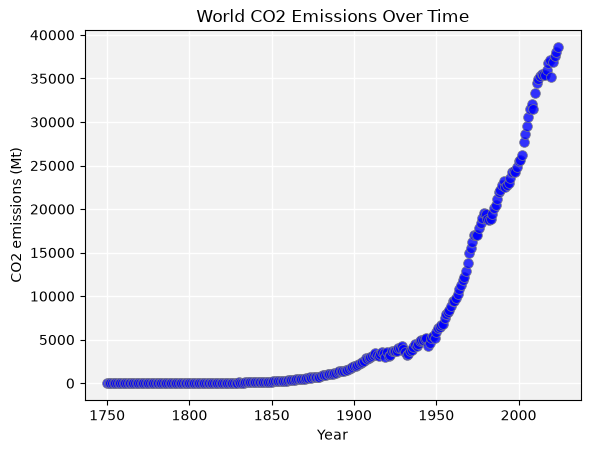

In [5]:
ax = world_co2_df.plot.scatter(
    x="year",
    y="co2",
    title="World CO2 Emissions Over Time",
    xlabel="Year",
    ylabel="CO2 emissions (Mt)",
    marker="o",  # shape of the points
    c="blue",  # color of the points
    s=50,  # size of the points
    edgecolor="grey",  # edge color of the points
    linewidth=0.6,  # edge line width of the points
    alpha=0.8,  # transparency of the points
)
ax.figure.set_facecolor("white")  # the whole figure (outside the axes)
ax.set_facecolor("#f2f2f2")  # the plotting area (inside the axes)

ax.grid(color="white", linewidth=1)
ax.set_axisbelow(True)

## 3. Sliding Window: turning a time series into input–output pairs

In [6]:
def make_window_df(df, window_size=4, col="co2", year_col="year"):
    """Use `window_size` consecutive years of `col` as inputs and the next year's value as the target."""
    df = df.sort_values(year_col).reset_index(drop=True)
    values = df[col].to_numpy()
    years = df[year_col].to_numpy()

    rows = []
    for i in range(len(df) - window_size):
        row = {f"{col}_t-{window_size - j}": values[i + j] for j in range(window_size)}
        row["target_year"] = years[i + window_size]
        row[f"{col}_target"] = values[i + window_size]
        rows.append(row)

    return pd.DataFrame(rows)


window_df = make_window_df(world_co2_df, window_size=4)
window_df

,co2_t-4,co2_t-3,co2_t-2,co2_t-1,target_year,co2_target
0,9.306,9.407,9.505,9.610,1754,9.734
1,9.407,9.505,9.610,9.734,1755,9.793
2,9.505,9.610,9.734,9.793,1756,9.910
3,9.610,9.734,9.793,9.910,1757,10.094
4,9.734,9.793,9.910,10.094,1758,10.216
...,...,...,...,...,...,...
266,35392.832,35974.609,36734.004,37086.566,2020,35158.230
267,35974.609,36734.004,37086.566,35158.230,2021,36866.863
268,36734.004,37086.566,35158.230,36866.863,2022,37527.773
269,37086.566,35158.230,36866.863,37527.773,2023,38094.039


## 4. Split Datasets into Training and Testing

### We don't use `RANDOM SHUFFLE` to our dataset in a time-series training problem

With time series, a `random shuffle` lets the model learn from the future and then
get tested on the past. That leaks information, and the test score ends up better
than the model can really do.

- **The models sees the future during training**: In real use you forecast 2025
  using only data up to 2024. With a random split, the training set can include
  2019 and 2021 while 2020 is in the test set, so the model learns from years
  after the one it's predicting. That never happens in a real forecast.

- **Shuffling ignores the order in the data**: A random split treats the rows as
  independent, but in a time series they aren't.

**The rule**: _train on the past and test on the future_. That's what the following `70/30`
split by `target_year` does.

In [7]:
window_df = window_df.sort_values("target_year").reset_index(drop=True)

split_idx = int(len(window_df) * 0.7)
train_df = window_df.iloc[:split_idx]
test_df = window_df.iloc[split_idx:]

feature_cols = ["co2_t-4", "co2_t-3", "co2_t-2", "co2_t-1"]
X_train, y_train = train_df[feature_cols], train_df["co2_target"]
X_test, y_test = test_df[feature_cols], test_df["co2_target"]

print(
    f"Train: {train_df['target_year'].min()}–{train_df['target_year'].max()} ({len(train_df)} rows), percentage: {len(train_df) / len(window_df):.2%}"
)
print(
    f"Test:  {test_df['target_year'].min()}–{test_df['target_year'].max()} ({len(test_df)} rows), percentage: {len(test_df) / len(window_df):.2%}"
)

Train: 1754–1942 (189 rows), percentage: 69.74%
Test:  1943–2024 (82 rows), percentage: 30.26%


## 5. Build Random Forest Model for CO2 emission Prediction

`RandomForestRegressor`: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html

In [8]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(n_estimators=50)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(f"Model Training R^2 score: {model.score(X_train, y_train)}")
print(f"Model Testing R^2 score: {model.score(X_test, y_test)}")

Model Training R^2 score: 0.9989727618199578
Model Testing R^2 score: -2.1352030569577245


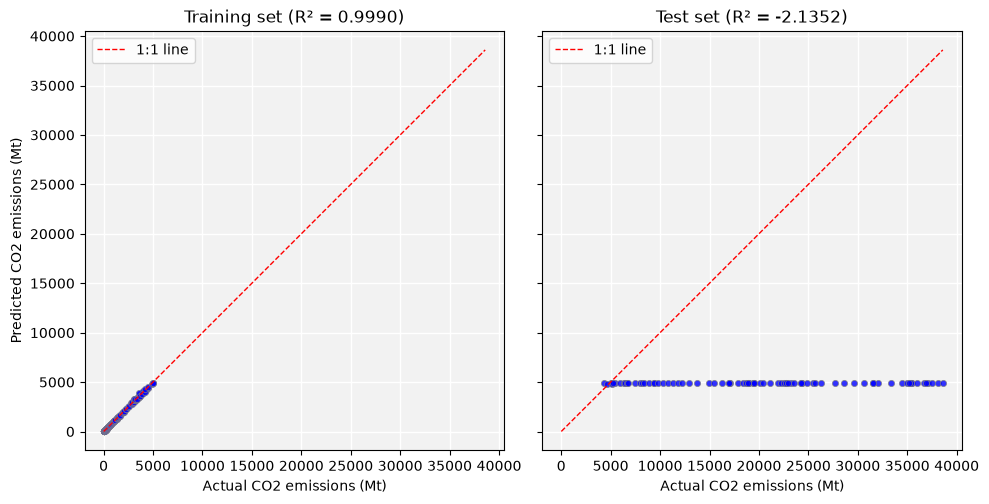

In [9]:
# Crossplots of actual vs. predicted values for the training and test sets
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)
for ax, X_set, y_true, y_hat, name in zip(
    axes,
    [X_train, X_test],
    [y_train, y_test],
    [y_train_pred, y_test_pred],
    ["Training", "Test"],
):
    ax.scatter(
        y_true,
        y_hat,
        c="blue",
        s=20,
        edgecolor="grey",
        linewidth=0.6,
        alpha=0.8,
    )
    ax.set_title(f"{name} set (R² = {model.score(X_set, y_true):.4f})")
    ax.set_xlabel("Actual CO2 emissions (Mt)")

# 1:1 line: points on this line are perfect predictions
lims = [
    min(y_train.min(), y_test.min(), y_train_pred.min(), y_test_pred.min()),
    max(y_train.max(), y_test.max(), y_train_pred.max(), y_test_pred.max()),
]
for ax in axes:
    ax.plot(lims, lims, color="red", linestyle="--", linewidth=1, label="1:1 line")
    ax.set_aspect("equal")
    ax.legend()
axes[0].set_ylabel("Predicted CO2 emissions (Mt)")

fig.set_facecolor("white")
for ax in axes:
    ax.set_facecolor("#f2f2f2")
    ax.grid(color="white", linewidth=1)
    ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

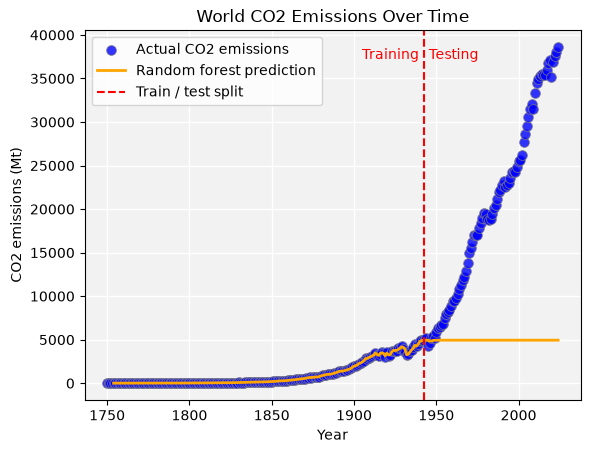

In [10]:
ax = world_co2_df.plot.scatter(
    x="year",
    y="co2",
    title="World CO2 Emissions Over Time",
    xlabel="Year",
    ylabel="CO2 emissions (Mt)",
    marker="o",  # shape of the points
    c="blue",  # color of the points
    s=50,  # size of the points
    edgecolor="grey",  # edge color of the points
    linewidth=0.6,  # edge line width of the points
    alpha=0.8,  # transparency of the points
    label="Actual CO2 emissions",
)
ax.figure.set_facecolor("white")  # the whole figure (outside the axes)
ax.set_facecolor("#f2f2f2")  # the plotting area (inside the axes)

ax.grid(color="white", linewidth=1)
ax.set_axisbelow(True)

# Random forest predictions for every target year (training + testing)
ax.plot(
    window_df["target_year"],
    model.predict(window_df[feature_cols]),
    color="orange",
    linewidth=2,
    label="Random forest prediction",
)

# Vertical line halfway between the last training year and the first test year
split_year = (train_df["target_year"].max() + test_df["target_year"].min()) / 2
ax.axvline(
    split_year, color="red", linestyle="--", linewidth=1.5, label="Train / test split"
)
ax.text(
    split_year - 3,
    ax.get_ylim()[1] * 0.95,
    "Training",
    ha="right",
    va="top",
    color="red",
)
ax.text(
    split_year + 3, ax.get_ylim()[1] * 0.95, "Testing", ha="left", va="top", color="red"
)
ax.legend(loc="upper left")

### Why Random Forest failed to predict co2 emission in testing dataset?

- Because co2 emission data is simply increasing with time, traning data only covers
  `1754-1942`, where co2 tops out around `5,000 Mt`, that is the maximum value for
  the prediction model is trained.
- All test inputs are CO2 values from `1943 - 2024`, roughly `5,000 - 38,000 Mt`.
  Training model never sees those high co2 emission values before.
- Random Forest model is overfitting in training dataset.

## 6. Build Random Forest `CO2 Growth Model`

A random forest can only predict values inside the range of its training targets. CO2
emissions keep rising, so the test years are always outside that range.

The yearly **growth percentage** doesn't have that problem. It stays within a similar
range (roughly `-20%` to `+30%`) across all years, so test rows land inside the range
the model was trained on.

**Steps**:

1. Convert CO2 into yearly growth: `growth_t = (co2_t - co2_t-1) / co2_t-1 * 100`
2. Use the previous 4 years of growth as inputs and the next year's growth as the target
3. Convert the predicted growth back to CO2: `co2_t = co2_t-1 * (1 + growth_t / 100)`

In [11]:
# Yearly growth percentage of CO2 emissions

growth_df = (
    world_co2_df.assign(co2_growth=world_co2_df["co2"].pct_change() * 100)
    .dropna()
    .reset_index(drop=True)
)
growth_df.head(10)

,year,co2,co2_growth
0,1751,9.407,1.085321
1,1752,9.505,1.041777
2,1753,9.610,1.104682
3,1754,9.734,1.290323
4,1755,9.793,0.606123
5,1756,9.910,1.194731
6,1757,10.094,1.856710
7,1758,10.216,1.208639
8,1759,10.339,1.203994
9,1760,10.514,1.692620


In [12]:
# Create a windowed dataset for the growth of CO2 emissions
# - Features: previous 4 years' growth of CO2 emissions are used as features
# - Target: the target variable will be the growth of CO2 emissions in the current year

growth_window_df = make_window_df(growth_df, window_size=4, col="co2_growth")
growth_window_df.head(10)


,co2_growth_t-4,co2_growth_t-3,co2_growth_t-2,co2_growth_t-1,target_year,co2_growth_target
0,1.085321,1.041777,1.104682,1.290323,1755,0.606123
1,1.041777,1.104682,1.290323,0.606123,1756,1.194731
2,1.104682,1.290323,0.606123,1.194731,1757,1.856710
3,1.290323,0.606123,1.194731,1.856710,1758,1.208639
4,0.606123,1.194731,1.856710,1.208639,1759,1.203994
5,1.194731,1.856710,1.208639,1.203994,1760,1.692620
6,1.856710,1.208639,1.203994,1.692620,1761,2.225604
7,1.208639,1.203994,1.692620,2.225604,1762,1.898028
8,1.203994,1.692620,2.225604,1.898028,1763,2.191381
9,1.692620,2.225604,1.898028,2.191381,1764,1.831665


In [13]:
# Add absolute co2 emission values for previous and current years

co2_by_year = world_co2_df.set_index("year")["co2"]

# add previous year's CO2 emission as co2_prev, so we can convert co2 growth
# back to actual co2 emission for current year
growth_window_df["co2_prev"] = co2_by_year.loc[
    growth_window_df["target_year"] - 1
].to_numpy()

# add current year's CO2 emission as co2_target
growth_window_df["co2_target"] = co2_by_year.loc[
    growth_window_df["target_year"]
].to_numpy()

growth_window_df.head(10)


,co2_growth_t-4,co2_growth_t-3,co2_growth_t-2,co2_growth_t-1,target_year,co2_growth_target,co2_prev,co2_target
0,1.085321,1.041777,1.104682,1.290323,1755,0.606123,9.734,9.793
1,1.041777,1.104682,1.290323,0.606123,1756,1.194731,9.793,9.910
2,1.104682,1.290323,0.606123,1.194731,1757,1.856710,9.910,10.094
3,1.290323,0.606123,1.194731,1.856710,1758,1.208639,10.094,10.216
4,0.606123,1.194731,1.856710,1.208639,1759,1.203994,10.216,10.339
5,1.194731,1.856710,1.208639,1.203994,1760,1.692620,10.339,10.514
6,1.856710,1.208639,1.203994,1.692620,1761,2.225604,10.514,10.748
7,1.208639,1.203994,1.692620,2.225604,1762,1.898028,10.748,10.952
8,1.203994,1.692620,2.225604,1.898028,1763,2.191381,10.952,11.192
9,1.692620,2.225604,1.898028,2.191381,1764,1.831665,11.192,11.397


In [14]:
# Same 70/30 split by target_year: train on the past, test on the future

split_idx = int(len(growth_window_df) * 0.7)
g_train_df = growth_window_df.iloc[:split_idx]
g_test_df = growth_window_df.iloc[split_idx:]

# input features for the growth model
growth_cols = ["co2_growth_t-4", "co2_growth_t-3", "co2_growth_t-2", "co2_growth_t-1"]

Xg_train, yg_train = g_train_df[growth_cols], g_train_df["co2_growth_target"]
Xg_test, yg_test = g_test_df[growth_cols], g_test_df["co2_growth_target"]

print(
    f"Train: {g_train_df['target_year'].min()}–{g_train_df['target_year'].max()} ({len(g_train_df)} rows), percentage: {len(g_train_df) / len(growth_window_df) * 100:.2f}%"
)
print(
    f"Test:  {g_test_df['target_year'].min()}–{g_test_df['target_year'].max()} ({len(g_test_df)} rows), percentage: {len(g_test_df) / len(growth_window_df) * 100:.2f}%"
)

print(f"Train growth range: {yg_train.min():.1f}% to {yg_train.max():.1f}%")
print(f"Test growth range:  {yg_test.min():.1f}% to {yg_test.max():.1f}%")

Train: 1755–1943 (189 rows), percentage: 70.00%
Test:  1944–2024 (81 rows), percentage: 30.00%
Train growth range: -26.7% to 34.2%
Test growth range:  -16.9% to 14.0%


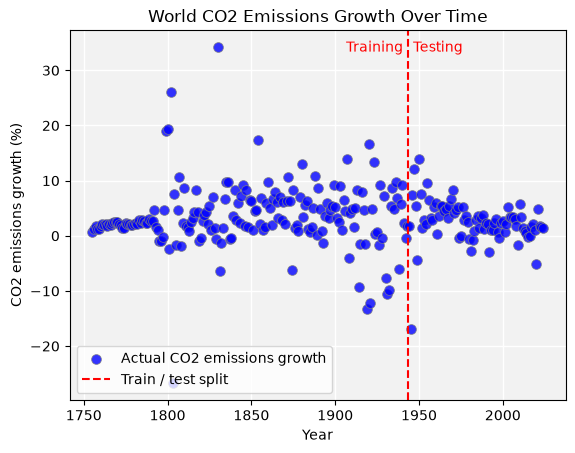

In [15]:
ax = growth_window_df.plot.scatter(
    x="target_year",
    y="co2_growth_target",
    title="World CO2 Emissions Growth Over Time",
    xlabel="Year",
    ylabel="CO2 emissions growth (%)",
    marker="o",  # shape of the points
    c="blue",  # color of the points
    s=50,  # size of the points
    edgecolor="grey",  # edge color of the points
    linewidth=0.6,  # edge line width of the points
    alpha=0.8,  # transparency of the points
    label="Actual CO2 emissions growth",
)
ax.figure.set_facecolor("white")  # the whole figure (outside the axes)
ax.set_facecolor("#f2f2f2")  # the plotting area (inside the axes)

ax.grid(color="white", linewidth=1)
ax.set_axisbelow(True)

# Vertical line halfway between the last training year and the first test year
split_year = (g_train_df["target_year"].max() + g_test_df["target_year"].min()) / 2
ax.axvline(
    split_year, color="red", linestyle="--", linewidth=1.5, label="Train / test split"
)

ax.text(
    split_year - 3,
    ax.get_ylim()[1] * 0.95,
    "Training",
    ha="right",
    va="top",
    color="red",
)
ax.text(
    split_year + 3,
    ax.get_ylim()[1] * 0.95,
    "Testing",
    ha="left",
    va="top",
    color="red",
)
ax.legend(loc="lower left")
plt.show()

In [16]:
from sklearn.metrics import r2_score

growth_model = RandomForestRegressor(n_estimators=50)
growth_model.fit(Xg_train, yg_train)

print(
    f"CO2 growth Training R^2 scores: {r2_score(yg_train, growth_model.predict(Xg_train)):.4f}"
)
print(
    f"CO2 growth Testing R^2 scores: {r2_score(yg_test, growth_model.predict(Xg_test)):.4f}"
)

# Convert predicted growth back to CO2: co2_t = co2_t-1 * (1 + growth_t / 100)
g_train_co2_pred = g_train_df["co2_prev"] * (1 + growth_model.predict(Xg_train) / 100)
g_test_co2_pred = g_test_df["co2_prev"] * (1 + growth_model.predict(Xg_test) / 100)

print(
    f"CO2 Training R^2 score: {r2_score(g_train_df['co2_target'], g_train_co2_pred):.4f}"
)
print(
    f"CO2 Testing R^2 score: {r2_score(g_test_df['co2_target'], g_test_co2_pred):.4f}"
)

# calculate baseline CO2 R^2 score: using the previous year's CO2 as the prediction
print(
    f"Baseline CO2 R^2 score: {r2_score(g_test_df['co2_target'], g_test_df['co2_prev']):.4f}"
)


CO2 growth Training R^2 scores: 0.8257
CO2 growth Testing R^2 scores: -0.3042
CO2 Training R^2 score: 0.9988
CO2 Testing R^2 score: 0.9954
Baseline CO2 R^2 score: 0.9959


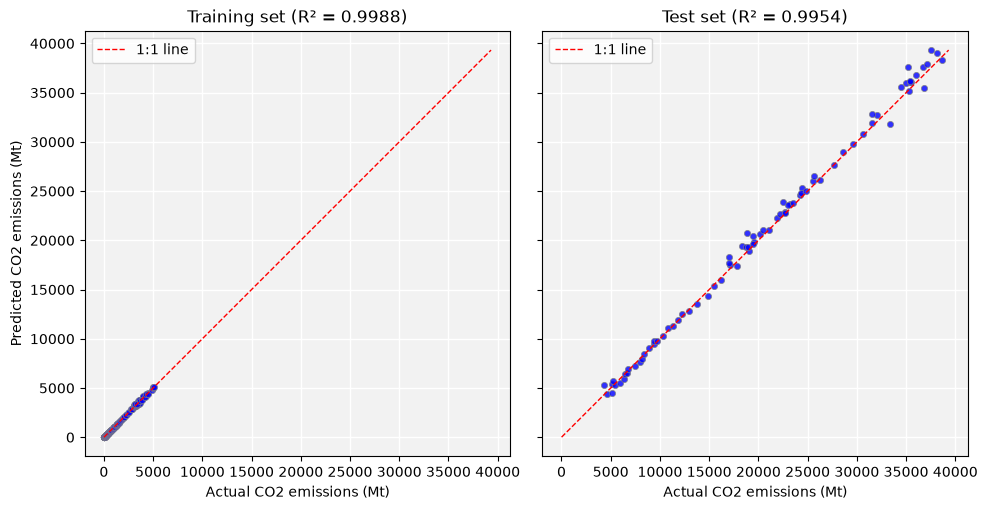

In [17]:
# Crossplots of actual vs. predicted CO2 for the training and test sets
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)

for ax, y_true, y_hat, name in zip(
    axes,
    [g_train_df["co2_target"], g_test_df["co2_target"]],
    [g_train_co2_pred, g_test_co2_pred],
    ["Training", "Test"],
):
    ax.scatter(
        y_true,
        y_hat,
        c="blue",
        s=20,
        edgecolor="grey",
        linewidth=0.6,
        alpha=0.8,
    )
    ax.set_title(f"{name} set (R² = {r2_score(y_true, y_hat):.4f})")
    ax.set_xlabel("Actual CO2 emissions (Mt)")

# 1:1 line: points on this line are perfect predictions
lims = [
    min(
        growth_window_df["co2_target"].min(),
        g_train_co2_pred.min(),
        g_test_co2_pred.min(),
    ),
    max(
        growth_window_df["co2_target"].max(),
        g_train_co2_pred.max(),
        g_test_co2_pred.max(),
    ),
]
for ax in axes:
    ax.plot(lims, lims, color="red", linestyle="--", linewidth=1, label="1:1 line")
    ax.set_aspect("equal")
    ax.legend()

axes[0].set_ylabel("Predicted CO2 emissions (Mt)")
fig.set_facecolor("white")

for ax in axes:
    ax.set_facecolor("#f2f2f2")
    ax.grid(color="white", linewidth=1)
    ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

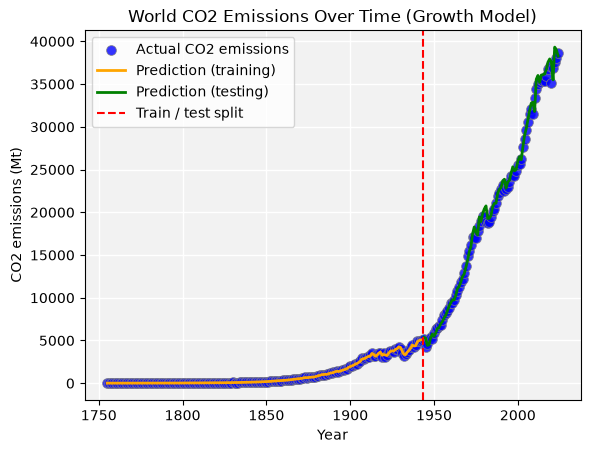

In [18]:
ax = growth_window_df.plot.scatter(
    x="target_year",
    y="co2_target",
    title="World CO2 Emissions Over Time (Growth Model)",
    xlabel="Year",
    ylabel="CO2 emissions (Mt)",
    marker="o",  # shape of the points
    c="blue",  # color of the points
    s=50,  # size of the points
    edgecolor="grey",  # edge color of the points
    linewidth=0.6,  # edge line width of the points
    alpha=0.8,  # transparency of the points
    label="Actual CO2 emissions",
)
ax.figure.set_facecolor("white")  # the whole figure (outside the axes)
ax.set_facecolor("#f2f2f2")  # the plotting area (inside the axes)

ax.grid(color="white", linewidth=1)
ax.set_axisbelow(True)

# Growth model predictions converted back to CO2, colored by training / testing
ax.plot(
    g_train_df["target_year"],
    g_train_co2_pred,
    color="orange",
    linewidth=2,
    label="Prediction (training)",
)
ax.plot(
    g_test_df["target_year"],
    g_test_co2_pred,
    color="green",
    linewidth=2,
    label="Prediction (testing)",
)

# Vertical line halfway between the last training year and the first test year
split_year = (g_train_df["target_year"].max() + g_test_df["target_year"].min()) / 2
ax.axvline(
    split_year, color="red", linestyle="--", linewidth=1.5, label="Train / test split"
)
ax.legend(loc="upper left")
plt.show()

### What changed?

- **The CO2 test predictions are no longer flat**: The test R² goes from negative (section 5)
  to about `0.99`, because the model now predicts growth, which stays inside the training range.
- **But the growth itself is hard to predict**: The growth testing R² is close to or below `0`.
  Next year's growth depends on events (wars, recessions, COVID-19 in 2020) that the past 4 years
  of growth can't show.
- **Compare with the baseline**: Simply using last year's CO2 as the prediction gets about the same
  test R². Most of the good CO2 score comes from `co2_t-1`, not from the model.

$co2\_t = (co2\_t-1) * (1 + \frac{growth\_t}{100})$

**Lesson**: Always compare a time series model with a simple baseline. A high R² doesn't mean the
model learned anything useful.